# 01 · Teoría: softmax y temperatura

**Objetivo de este cuaderno:** entender el softmax, el papel de la **temperatura** \(T\), el «conocimiento oscuro» del profesor y la **pérdida de destilación**, con figuras y un ejemplo numérico pequeño. Aquí no se entrenan redes: solo se fija el lenguaje que usan los cuadernos 02 y 03.

## Softmax

Un clasificador no produce directamente una clase: produce un vector de **logits** \(z\) (números reales, uno por clase). El softmax los convierte en una distribución de probabilidad:

$$
p_i = \mathrm{softmax}(z)_i = \frac{e^{z_i}}{\sum_j e^{z_j}}.
$$

La clase predicha es \(\arg\max_i p_i\) (equivale a \(\arg\max_i z_i\)). Lo que cambia, y lo que el estudiante va a copiar, es *cómo se reparte* la probabilidad entre las clases no ganadoras.


In [1]:
from pathlib import Path
import os, sys, json, time, gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _raiz():
    aqui = Path.cwd().resolve()
    for cand in [aqui, *aqui.parents]:
        if (cand / "src" / "destilacion_utils.py").exists() and (cand / "notebooks").is_dir():
            return cand
    raise FileNotFoundError(
        "No encuentro la raiz del proyecto de destilacion "
        "(src/destilacion_utils.py + notebooks/)."
    )

RAIZ = _raiz()
sys.path.insert(0, str(RAIZ / "src"))

from destilacion_utils import (
    preparar_rutas,
    fijar_semilla,
    dispositivo,
    configurar_proxy_y_hf,
    comprobar_entorno,
    probar_conexion_hf,
    texto_ayuda_proxy,
    softmax_temperatura,
    divergencia_kl,
    perdida_destilacion,
    construir_mlp,
    construir_estudiante_sentimiento,
    contar_parametros,
    tamano_archivo_mb,
    guardar_json,
    cargar_json,
    guardar_checkpoint,
    cargar_checkpoint,
    evaluar_loader,
    medir_latencia_ms,
    entrenar_epoca,
)

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    import matplotlib
    matplotlib.use("Agg")

plt.rcParams.update({
    "figure.figsize": (8, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 12,
    "figure.dpi": 110,
})

RUTAS = preparar_rutas(RAIZ)
SEMILLA = fijar_semilla()
CFG_RED = configurar_proxy_y_hf(RAIZ, verbose=True)
DEVICE = dispositivo()
print(f"Raiz:        {RAIZ}")
print(f"Dispositivo: {DEVICE}")
print(f"Semilla:     {SEMILLA}")


Configuración de red y Hugging Face
  HTTP_PROXY definido:  False
  HTTPS_PROXY definido: False
  NO_PROXY definido:    False
  Certificado SSL (SSL_CERT_FILE / REQUESTS_CA_BUNDLE): False
  Token de Hugging Face presente: False (no se muestra el valor)
  HF_HOME: /workspace/destilacion/cache-hf
  Modo offline HF: False
  Ajustes aplicados en esta sesión:
    - HF_HUB_DISABLE_TELEMETRY=1
Raiz:        /workspace/destilacion
Dispositivo: cpu
Semilla:     42


## 1. Softmax a mano, y de forma numéricamente estable

Restar el máximo de los logits antes de exponentiar no cambia el resultado (el factor se cancela) y evita desbordar `exp` cuando los logits son grandes. `softmax_temperatura` del módulo compartido hace exactamente eso. Lo comprobamos con un vector pequeño.


In [2]:
logits = np.array([2.0, 1.0, 0.1])

def softmax_ingenua(z):
    e = np.exp(z)
    return e / e.sum()

def softmax_estable(z):
    z = z - z.max()
    e = np.exp(z)
    return e / e.sum()

p_ingenua = softmax_ingenua(logits)
p_estable = softmax_estable(logits)
p_util = softmax_temperatura(logits, temperature=1.0)

tabla = pd.DataFrame(
    {"clase": [0, 1, 2], "logit": logits, "ingenua": p_ingenua, "estable": p_estable, "util": p_util}
)
print(tabla.to_string(index=False))
print("sumas:", p_ingenua.sum(), p_estable.sum(), p_util.sum())
np.testing.assert_allclose(p_ingenua, p_estable)
np.testing.assert_allclose(p_estable, p_util)
print("Las tres implementaciones coinciden (T = 1).")


 clase  logit  ingenua  estable     util
     0    2.0 0.659001 0.659001 0.659001
     1    1.0 0.242433 0.242433 0.242433
     2    0.1 0.098566 0.098566 0.098566
sumas: 1.0 1.0 1.0
Las tres implementaciones coinciden (T = 1).


## 2. La temperatura \(T\)

En destilación se usa un softmax **con temperatura**:

$$
p_i^{(T)} = \mathrm{softmax}(z / T)_i = \frac{e^{z_i / T}}{\sum_j e^{z_j / T}}.
$$

- \(T = 1\): el softmax habitual.
- \(T > 1\): se suaviza la distribución. Las clases no ganadoras reciben más masa. Ahí es donde aparece el conocimiento oscuro.
- \(T \to 0\): la distribución se acerca a un vector *one-hot* (todo a la clase de mayor logit).
- \(T \to \infty\): se acerca a la uniforme.

La celda siguiente toma un mismo vector de logits (el de un «profesor» que está muy seguro de la clase 3, pero ve cierto parecido con la 8 y la 5) y lo muestra a varias temperaturas.


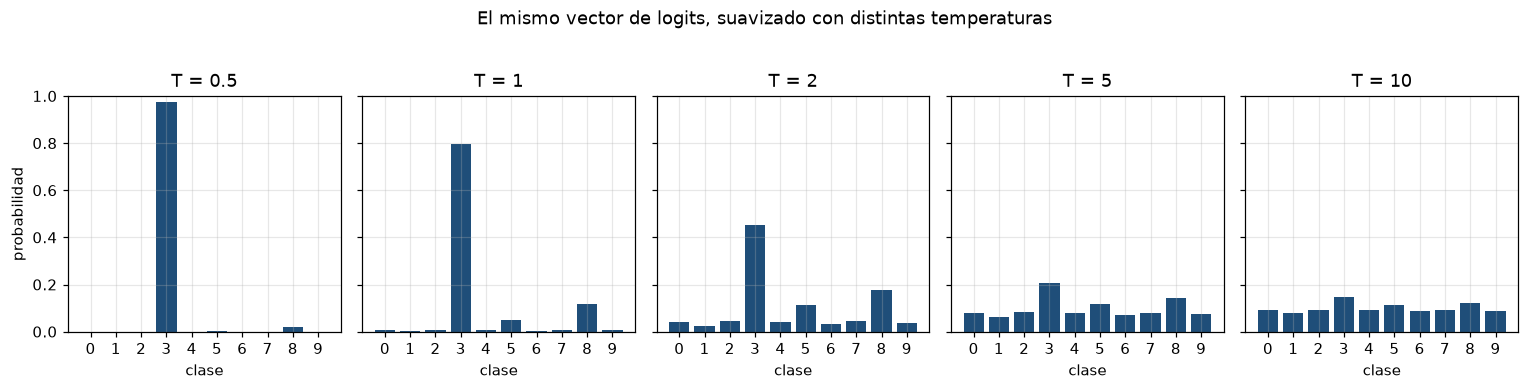

,0.5,1.0,2.0,5.0,10.0
clase 0,0.000,0.007,0.041,0.080,0.091
clase 1,0.000,0.002,0.023,0.063,0.081
clase 2,0.000,0.008,0.045,0.083,0.093
clase 3,0.974,0.794,0.454,0.208,0.147
clase 4,0.000,0.006,0.039,0.078,0.090
clase 5,0.004,0.048,0.112,0.119,0.111
clase 6,0.000,0.004,0.030,0.071,0.086
clase 7,0.000,0.007,0.043,0.081,0.092
clase 8,0.022,0.119,0.175,0.142,0.121
clase 9,0.000,0.005,0.037,0.076,0.089


In [3]:
clases = np.arange(10)
# Logits inventados de un profesor ante un dígito que es un 3.
# El 3 gana; el 8 y el 5 se le parecen; el 0 y el 1 casi no.
logits_profesor = np.array([0.2, -1.0, 0.4, 5.0, 0.1, 2.2, -0.4, 0.3, 3.1, 0.0])

temperaturas = [0.5, 1, 2, 5, 10]
probs = {T: softmax_temperatura(logits_profesor, temperature=T) for T in temperaturas}

fig, ejes = plt.subplots(1, len(temperaturas), figsize=(14, 3.4), sharey=True)
for ax, T in zip(ejes, temperaturas):
    ax.bar(clases, probs[T], color="#1f4e79")
    ax.set_title(f"T = {T}")
    ax.set_xticks(clases)
    ax.set_xlabel("clase")
    ax.set_ylim(0, 1)
ejes[0].set_ylabel("probabilidad")
fig.suptitle("El mismo vector de logits, suavizado con distintas temperaturas", y=1.03)
fig.tight_layout()
fig.savefig(RUTAS["resultados"] / "fig_softmax_temperatura.png", bbox_inches="tight")
plt.show()

pd.DataFrame(probs, index=[f"clase {i}" for i in clases]).round(3)


### Cómo leer la figura

Con \(T = 0.5\) casi toda la masa está en el 3: la señal se parece a una etiqueta dura. Con \(T = 5\) o \(T = 10\) el 3 sigue ganando, pero el 8 y el 5 son claramente más probables que el 0 o el 1. Esa es la información que queremos que el estudiante reciba.

Una forma compacta de medir el suavizado es la **entropía** \(H(p) = -\sum_i p_i \log p_i\): crece con \(T\) y se satura cerca de \(\log 10\) (uniforme en 10 clases).


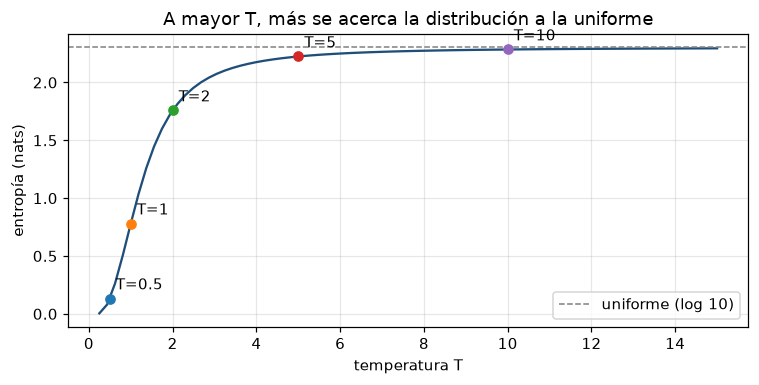

In [4]:
def entropia(p, eps=1e-12):
    p = np.clip(p, eps, 1.0)
    p = p / p.sum()
    return float(-(p * np.log(p)).sum())

Ts = np.linspace(0.25, 15, 80)
H = [entropia(softmax_temperatura(logits_profesor, temperature=T)) for T in Ts]

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(Ts, H, color="#1f4e79")
ax.axhline(np.log(10), color="gray", linestyle="--", linewidth=1, label="uniforme (log 10)")
for T in temperaturas:
    ax.scatter([T], [entropia(probs[T])], zorder=3)
    ax.annotate(f"T={T}", (T, entropia(probs[T])), textcoords="offset points", xytext=(4, 6))
ax.set_xlabel("temperatura T")
ax.set_ylabel("entropía (nats)")
ax.set_title("A mayor T, más se acerca la distribución a la uniforme")
ax.legend()
fig.tight_layout()
fig.savefig(RUTAS["resultados"] / "fig_entropia_temperatura.png", bbox_inches="tight")
plt.show()


## 3. La pérdida de destilación

Hinton, Vinyals y Dean (2015) combinan dos términos:

$$
\mathcal{L} = \alpha \, T^{2} \, \mathrm{KL}\big( p^{\text{prof}}_{(T)} \,\big\|\, p^{\text{est}}_{(T)} \big) + (1-\alpha)\, \mathrm{CE}\big(z^{\text{est}}, y\big).
$$

- **KL** (divergencia de Kullback-Leibler): obliga al estudiante a copiar la distribución suave del profesor. Se calcula a temperatura \(T\).
- **CE** (entropía cruzada): el estudiante también ve la etiqueta dura \(y\), la del dataset.
- **\(\alpha\)**: mezcla. \(\alpha = 1\) es solo destilación; \(\alpha = 0\) es el entrenamiento supervisado habitual.
- **\(T^2\)**: al subir \(T\), las probabilidades se aplanan y el gradiente de la KL se encoge (del orden de \(1/T^2\)). Multiplicar por \(T^2\) compensa ese efecto y deja el peso relativo de los dos términos más estable cuando cambias \(T\).

En el módulo compartido esto es `perdida_destilacion(...)`.


In [5]:
import torch

# Profesor: seguro del 3, con masa residual en 8 y 5 (el mismo vector de arriba).
z_prof = torch.tensor(logits_profesor, dtype=torch.float32).unsqueeze(0)
# Estudiante A: ya se parece al profesor. Estudiante B: se equivoca y apuesta por el 8.
z_est_a = torch.tensor([0.1, -0.8, 0.2, 4.2, 0.0, 1.8, -0.3, 0.2, 2.6, 0.0]).unsqueeze(0)
z_est_b = torch.tensor([0.3, 0.0, 0.2, 1.0, 0.1, 0.8, 0.0, 0.2, 4.8, 0.2]).unsqueeze(0)
y = torch.tensor([3])

filas = []
for nombre, z_est in [("estudiante cercano", z_est_a), ("estudiante que apuesta al 8", z_est_b)]:
    for T in [1.0, 3.0, 5.0]:
        for alpha in [0.0, 0.7, 1.0]:
            loss = perdida_destilacion(z_est, z_prof, y, temperature=T, alpha=alpha)
            filas.append(
                {"caso": nombre, "T": T, "alpha": alpha, "perdida": float(loss)}
            )

tabla_perdida = pd.DataFrame(filas).pivot_table(
    index=["caso", "T"], columns="alpha", values="perdida"
)
tabla_perdida.round(3)


alpha                              0.0    0.7    1.0
caso                        T                       
estudiante cercano          1.0  0.332  0.113  0.019
                            3.0  0.332  0.137  0.054
                            5.0  0.332  0.135  0.051
estudiante que apuesta al 8 1.0  3.902  3.069  2.712
                            3.0  3.902  2.576  2.007
                            5.0  3.902  2.304  1.618

### Cómo leer la tabla

- Con \(\alpha = 0\) solo cuenta la etiqueta dura. Si ambos estudiantes aciertan el 3 como clase más probable, esta pérdida no distingue bien *cómo* reparte cada uno el resto de la masa.
- Con \(\alpha = 0.7\) o \(1\), el estudiante que se parece al profesor tiene pérdida claramente menor que el que se empeña en el 8: la KL ve la forma de la distribución, no solo el ganador.

Eso es exactamente lo que queremos transferir en los cuadernos 02 y 03.


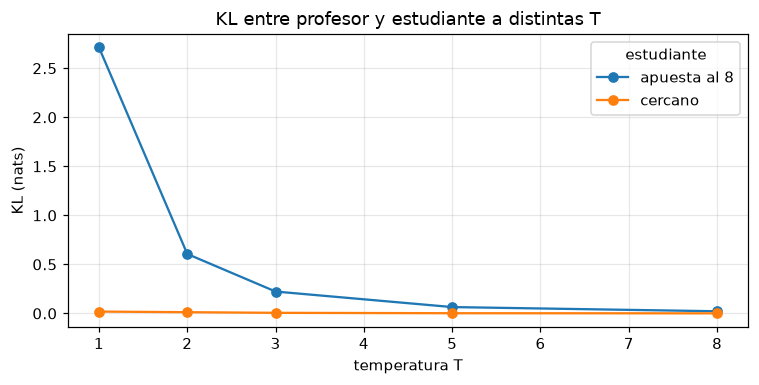

estudiante,apuesta al 8,cercano
T,,
1,2.712,0.019
2,0.606,0.012
3,0.223,0.006
5,0.065,0.002
8,0.022,0.001


In [6]:
# KL entre el profesor y un estudiante, a varias T, para el caso "cercano" y el "equivocado".
filas_kl = []
for nombre, z_est in [("cercano", z_est_a), ("apuesta al 8", z_est_b)]:
    for T in [1, 2, 3, 5, 8]:
        p = softmax_temperatura(z_prof.numpy().ravel(), temperature=T)
        q = softmax_temperatura(z_est.numpy().ravel(), temperature=T)
        filas_kl.append({"T": T, "estudiante": nombre, "KL(prof || est)": float(divergencia_kl(p, q))})

tabla_kl = pd.DataFrame(filas_kl).pivot(index="T", columns="estudiante", values="KL(prof || est)")
ax = tabla_kl.plot(marker="o", figsize=(7, 3.6), title="KL entre profesor y estudiante a distintas T")
ax.set_ylabel("KL (nats)")
ax.set_xlabel("temperatura T")
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(RUTAS["resultados"] / "fig_kl_temperatura.png", bbox_inches="tight")
plt.show()
tabla_kl.round(3)


## Qué retener

1. El softmax convierte logits en una distribución. La temperatura \(T\) controla cuánto se suaviza.
2. El valor de destilar está en las **clases no ganadoras**: el estudiante copia similitudes que la etiqueta dura no contiene.
3. La pérdida mezcla esa KL (con el factor \(T^2\)) y, si quieres, la entropía cruzada con \(y\). \(T\) y \(\alpha\) son hiperparámetros: se eligen con un conjunto de validación, no a ojo en test.
4. En 02 y 03 usaremos, salvo que se indique otra cosa, \(T = 3\) y \(\alpha = 0.7\), valores de partida razonables, no un óptimo universal.

Siguiente cuaderno: `02-destilacion-mnist-mlp.ipynb` (calentamiento en visión, un MLP). El 03 hace lo mismo con un profesor de Hugging Face. Los dos pueden cursarse en ese orden; el 04 los necesita a ambos.
